# №8. Глобальная бинаризация

Три скана и фотография текста. Сначала выбираем порог вручную, затем реализуем
метод Оцу и подбираем гамму. Яркость имеет диапазон 0–255; тексту соответствует 0,
бумаге — 255. Обработка выполняется NumPy. Источники изображений перечислены
в `../data/SOURCES.md`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'
plt.rcParams['image.interpolation'] = 'nearest'


def to_uint8(image):
    return np.clip(np.rint(image), 0, 255).astype(np.uint8)


def show_images(images, titles, cols=3, figsize=None):
    rows = (len(images) + cols - 1) // cols
    if figsize is None:
        figsize = (4 * cols, 3.2 * rows)
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, image, title in zip(axes.flat, images, titles):
        if image.ndim == 2:
            ax.imshow(image, vmin=0, vmax=255)
        else:
            ax.imshow(to_uint8(image))
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

1: shape=(384, 512), уровней=255, диапазон=0…255
2: shape=(625, 800), уровней=256, диапазон=0…255
3: shape=(200, 1005), уровней=256, диапазон=0…255
4: shape=(682, 460), уровней=223, диапазон=0…223


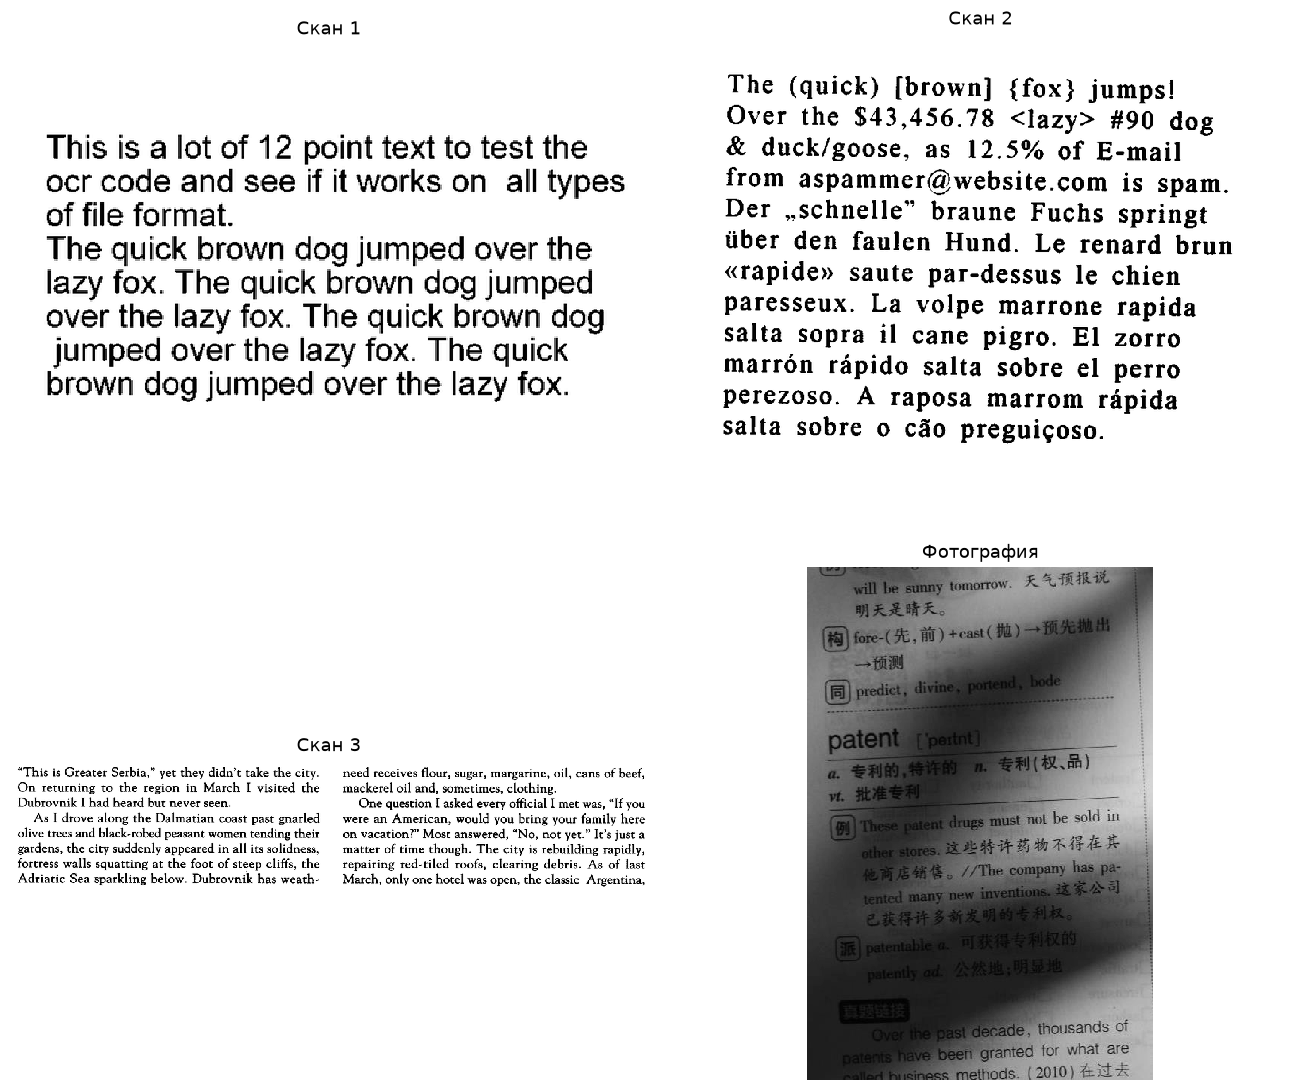

In [3]:
scans = [np.array(Image.open(f'data/text_scan_{i}.png').convert('L')) for i in range(1, 4)]
photo = np.array(Image.open('data/text_photo_2.jpg').convert('L'))
for i, image in enumerate([*scans, photo], 1):
    print(f'{i}: shape={image.shape}, уровней={len(np.unique(image))}, диапазон={image.min()}…{image.max()}')
show_images([*scans, photo], ['Скан 1', 'Скан 2', 'Скан 3', 'Фотография'], cols=2,
            figsize=(12, 10))

## 1. Порог и алгоритм Оцу

Порог $T$ делит яркости на два класса: $I\leq T$ и $I>T$.
Оцу выбирает максимум межклассовой дисперсии
$\sigma_B^2(T)=\omega_0\omega_1(\mu_0-\mu_1)^2$.
Накопленные суммы гистограммы дают веса и средние для всех 256 порогов.
При равенстве максимумов выбирается первый порог.

In [4]:
def binarize(image, threshold):
    """Чёрный текст: I <= T. Белый фон: I > T."""
    return np.where(np.asarray(image) <= threshold, 0, 255).astype(np.uint8)


def gamma_correct(image, gamma):
    """Гамма-коррекция с округлением результата к 8 битам."""
    return to_uint8(255 * (np.asarray(image, dtype=float) / 255) ** gamma)


def otsu_threshold(image):
    """Максимум межклассовой дисперсии для 256 уровней яркости."""
    image = to_uint8(image)
    counts = np.bincount(image.ravel(), minlength=256).astype(float)
    probability = counts / counts.sum()
    weight = np.cumsum(probability)
    moment = np.cumsum(probability * np.arange(256))
    total_mean = moment[-1]
    denominator = weight * (1 - weight)
    score = np.zeros(256)
    valid = denominator > 1e-12
    score[valid] = (total_mean * weight[valid] - moment[valid]) ** 2 / denominator[valid]
    if np.any(valid):
        return int(np.argmax(score))
    # Однородное изображение содержит единственный класс.
    return int(image.flat[0])

## 2. Ручной выбор для сканов

Сравниваем толщину штрихов, целостность букв и чистоту бумаги. Для каждого
скана показаны три соседних порога. Центральный вариант принят как ручная
разметка и используется ниже для сравнения гамм.

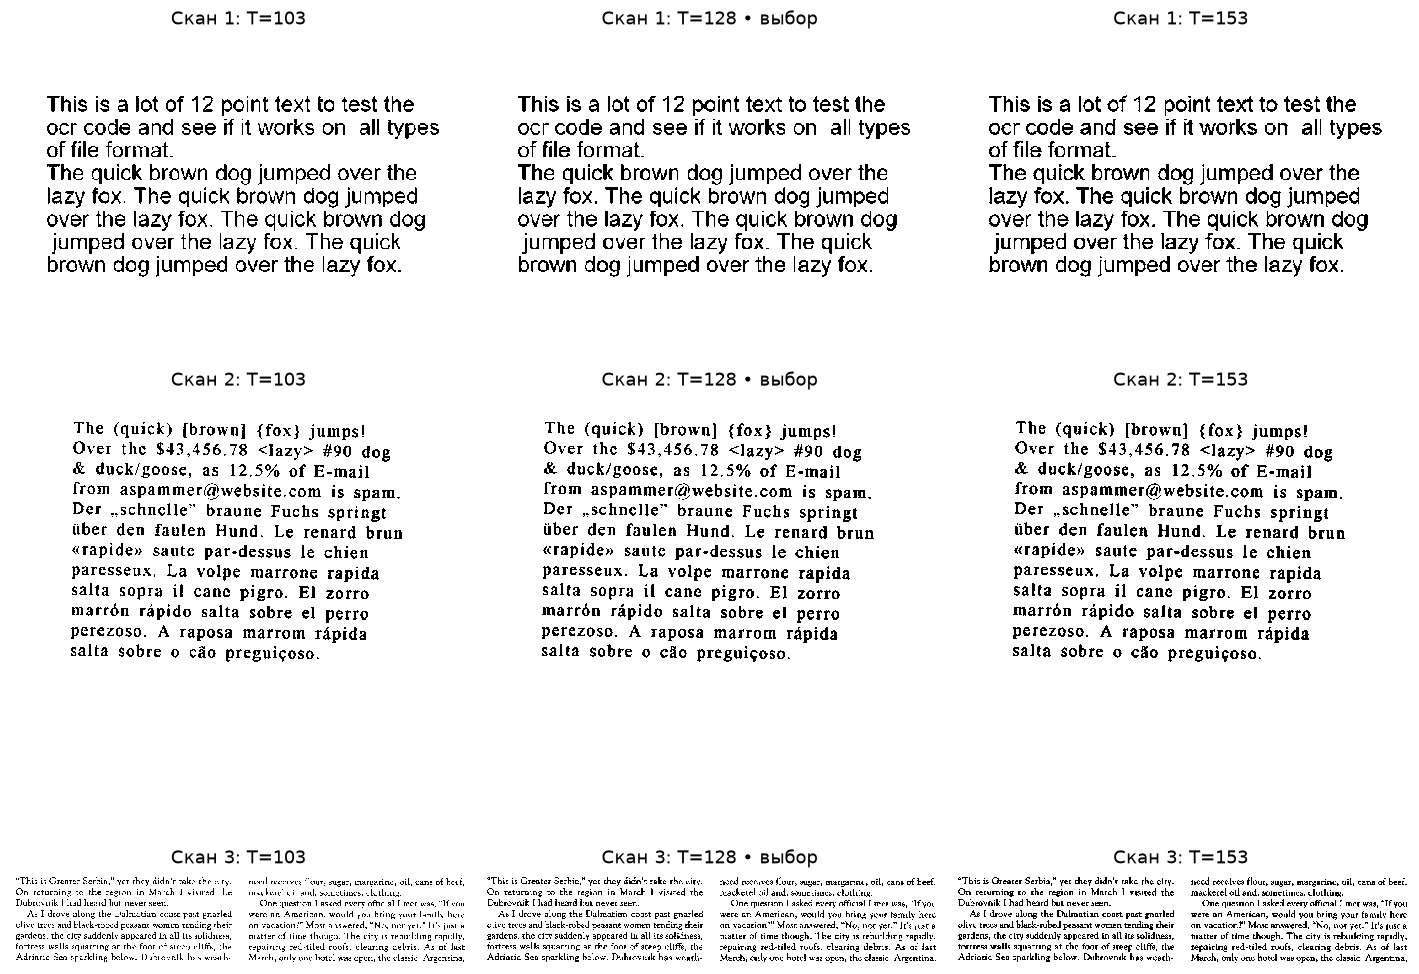

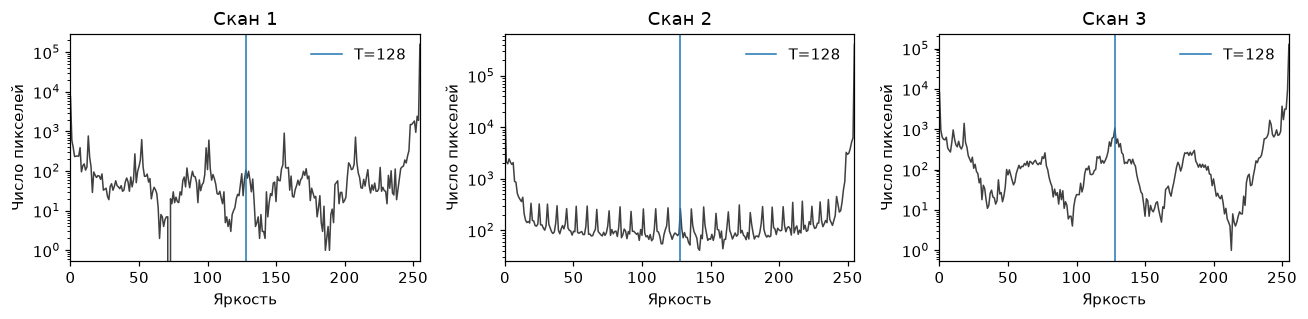

In [5]:
manual_thresholds = [128, 128, 128]
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for row, (scan, selected) in enumerate(zip(scans, manual_thresholds)):
    for col, threshold in enumerate([selected - 25, selected, selected + 25]):
        axes[row, col].imshow(binarize(scan, threshold), cmap='gray', vmin=0, vmax=255)
        axes[row, col].set_title(f'Скан {row + 1}: T={threshold}' + (' • выбор' if col == 1 else ''))
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for i, (scan, threshold, ax) in enumerate(zip(scans, manual_thresholds, axes), 1):
    ax.plot(np.bincount(scan.ravel(), minlength=256), color='0.25', lw=1)
    ax.axvline(threshold, color='tab:blue', lw=1, label=f'T={threshold}')
    ax.set(title=f'Скан {i}', xlabel='Яркость', ylabel='Число пикселей', xlim=(0, 255))
    ax.set_yscale('log')
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 3. Оцу и подбор гаммы

Используем $I_\gamma=255(I/255)^\gamma$. Для каждого скана перебираем гаммы
и сравниваем результат Оцу с выбранной вручную бинаризацией. Критерий —
доля отличающихся пикселей. При равном результате выбираем гамму ближе к 1.
Полученный оптимум относится к этой сетке и этой ручной разметке.

Скан 1: гамма  порог Оцу  отличие от ручной разметки, %
          0.35      149                 1.885
          0.50      143                 1.595
          0.70      145                 0.222
          1.00      140                 0.185
          1.40      141                 1.346
          2.00      137                 1.730
          3.00      134                 2.191
Выбор: гамма=1.0, ошибка=0.185%

Скан 2: гамма  порог Оцу  отличие от ручной разметки, %
          0.35      146                 1.644
          0.50      142                 1.051
          0.70      139                 0.465
          1.00      137                 0.183
          1.40      135                 0.642
          2.00      134                 1.129
          3.00      132                 1.632
Выбор: гамма=1.0, ошибка=0.183%

Скан 3: гамма  порог Оцу  отличие от ручной разметки, %
          0.35      151                 4.780
          0.50      148                 3.040
          0.70      140       

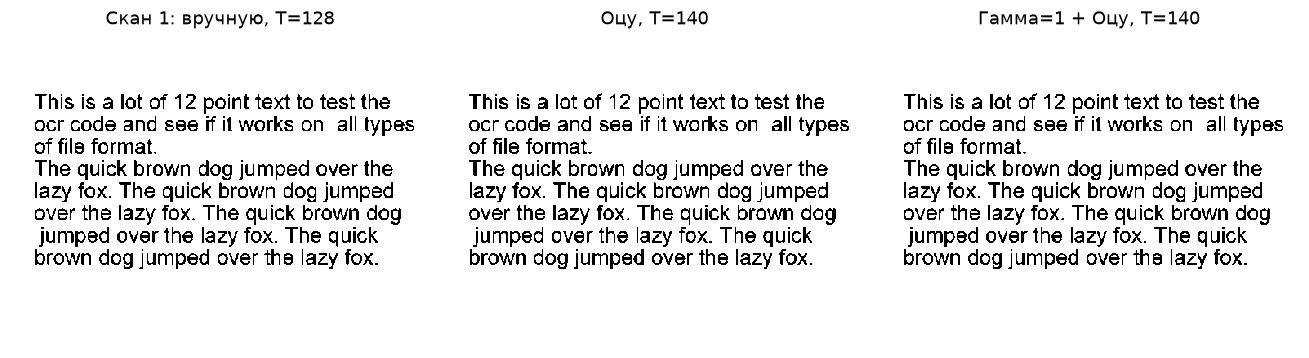

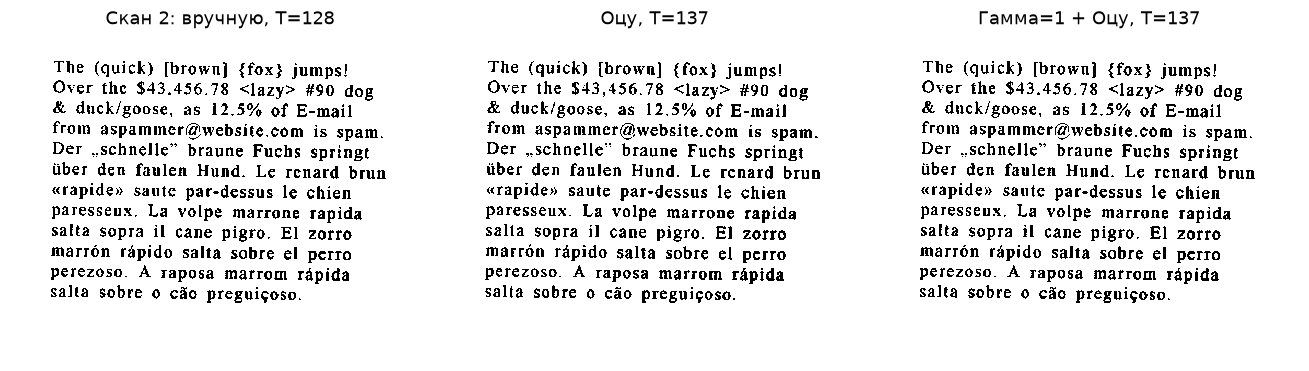

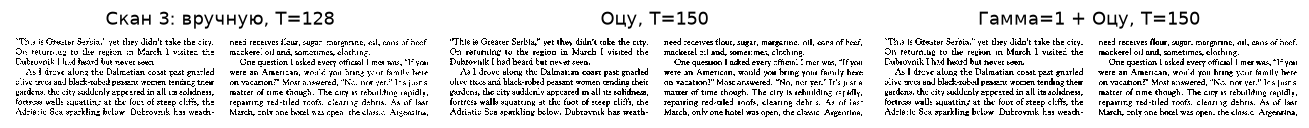

In [6]:
gammas = [0.35, 0.5, 0.7, 1.0, 1.4, 2.0, 3.0]
gamma_results = []
for i, (scan, manual_t) in enumerate(zip(scans, manual_thresholds), 1):
    reference = binarize(scan, manual_t)
    rows = []
    print(f'Скан {i}: гамма  порог Оцу  отличие от ручной разметки, %')
    for gamma in gammas:
        corrected = gamma_correct(scan, gamma)
        threshold = otsu_threshold(corrected)
        binary = binarize(corrected, threshold)
        error = np.mean(binary != reference)
        rows.append((error, abs(gamma - 1), gamma, threshold, binary))
        print(f'          {gamma:4.2f}      {threshold:3d}                {100 * error:6.3f}')
    best = min(rows, key=lambda row: row[:2])
    gamma_results.append(best)
    print(f'Выбор: гамма={best[2]}, ошибка={100 * best[0]:.3f}%\n')

for i, (scan, manual_t, best) in enumerate(zip(scans, manual_thresholds, gamma_results), 1):
    standard_t = otsu_threshold(scan)
    show_images([binarize(scan, manual_t), binarize(scan, standard_t), best[4]],
                [f'Скан {i}: вручную, T={manual_t}', f'Оцу, T={standard_t}',
                 f'Гамма={best[2]:g} + Оцу, T={best[3]}'], cols=3, figsize=(12, 4))

## 4. Фотография: тень и освещённая бумага

Глобальный порог действует одинаково во всём кадре. Проверим его на двух
фрагментах с разным освещением. Для каждого фрагмента порог Оцу задаёт
локальную опорную разметку; её качество оценивается по показанным буквам.

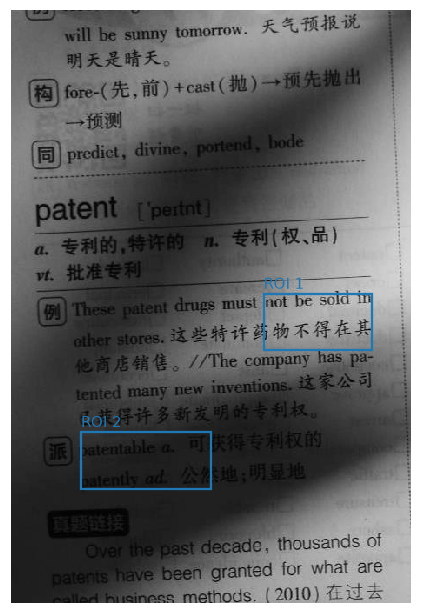

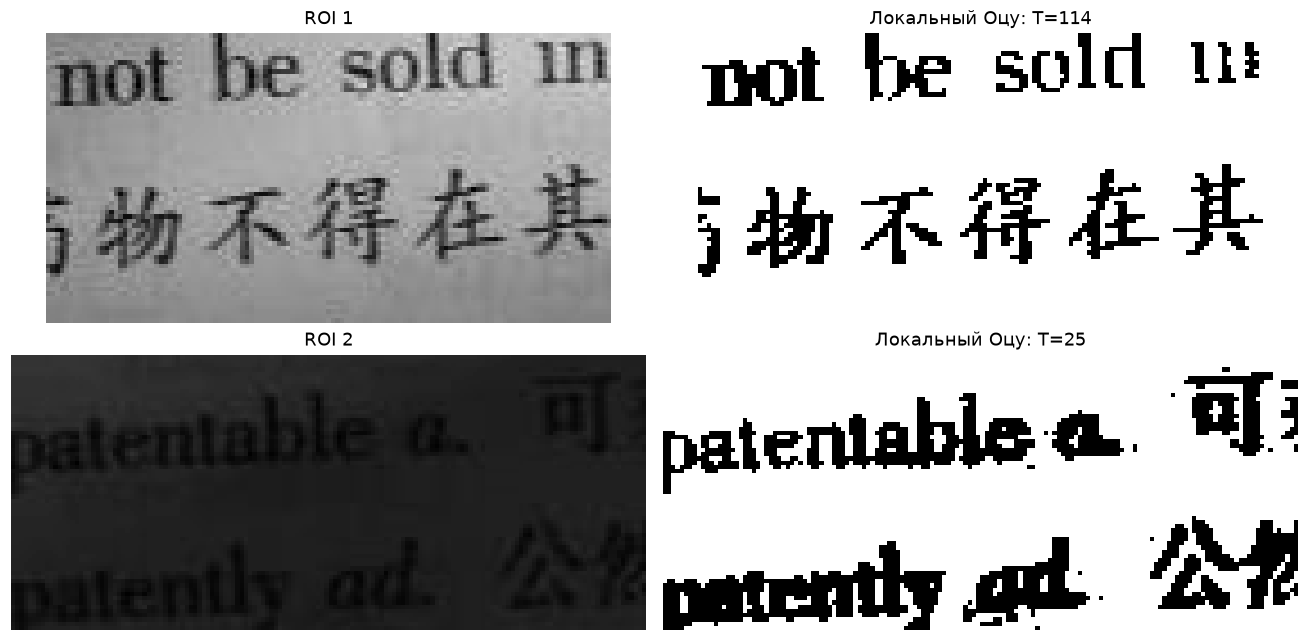

In [7]:
# Формат: (y0, y1, x0, x1). Области содержат текст и фон.
rois = [(326, 390, 290, 415), (485, 550, 80, 230)]
crops = [photo[y0:y1, x0:x1] for y0, y1, x0, x1 in rois]
local_thresholds = [otsu_threshold(crop) for crop in crops]
references = [binarize(crop, t) for crop, t in zip(crops, local_thresholds)]

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(photo, cmap='gray', vmin=0, vmax=255)
for i, (y0, y1, x0, x1) in enumerate(rois, 1):
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0,
                              fill=False, edgecolor='tab:blue', lw=1.5))
    ax.text(x0, y0 - 6, f'ROI {i}', color='tab:blue')
ax.axis('off')
plt.show()
show_images([crops[0], references[0], crops[1], references[1]],
            ['ROI 1', f'Локальный Оцу: T={local_thresholds[0]}',
             'ROI 2', f'Локальный Оцу: T={local_thresholds[1]}'], cols=2,
            figsize=(12, 6))

Лучший глобальный порог по ROI: 25
Остаточная ошибка: 1072 / 17750 (6.04%)
Глобальный Оцу: T=92, ошибка=7781 пикселей
Условия сохранения опорных классов: T >= 114 и T < 26.
Перекрытие яркостей текста и бумаги: 89 уровней.


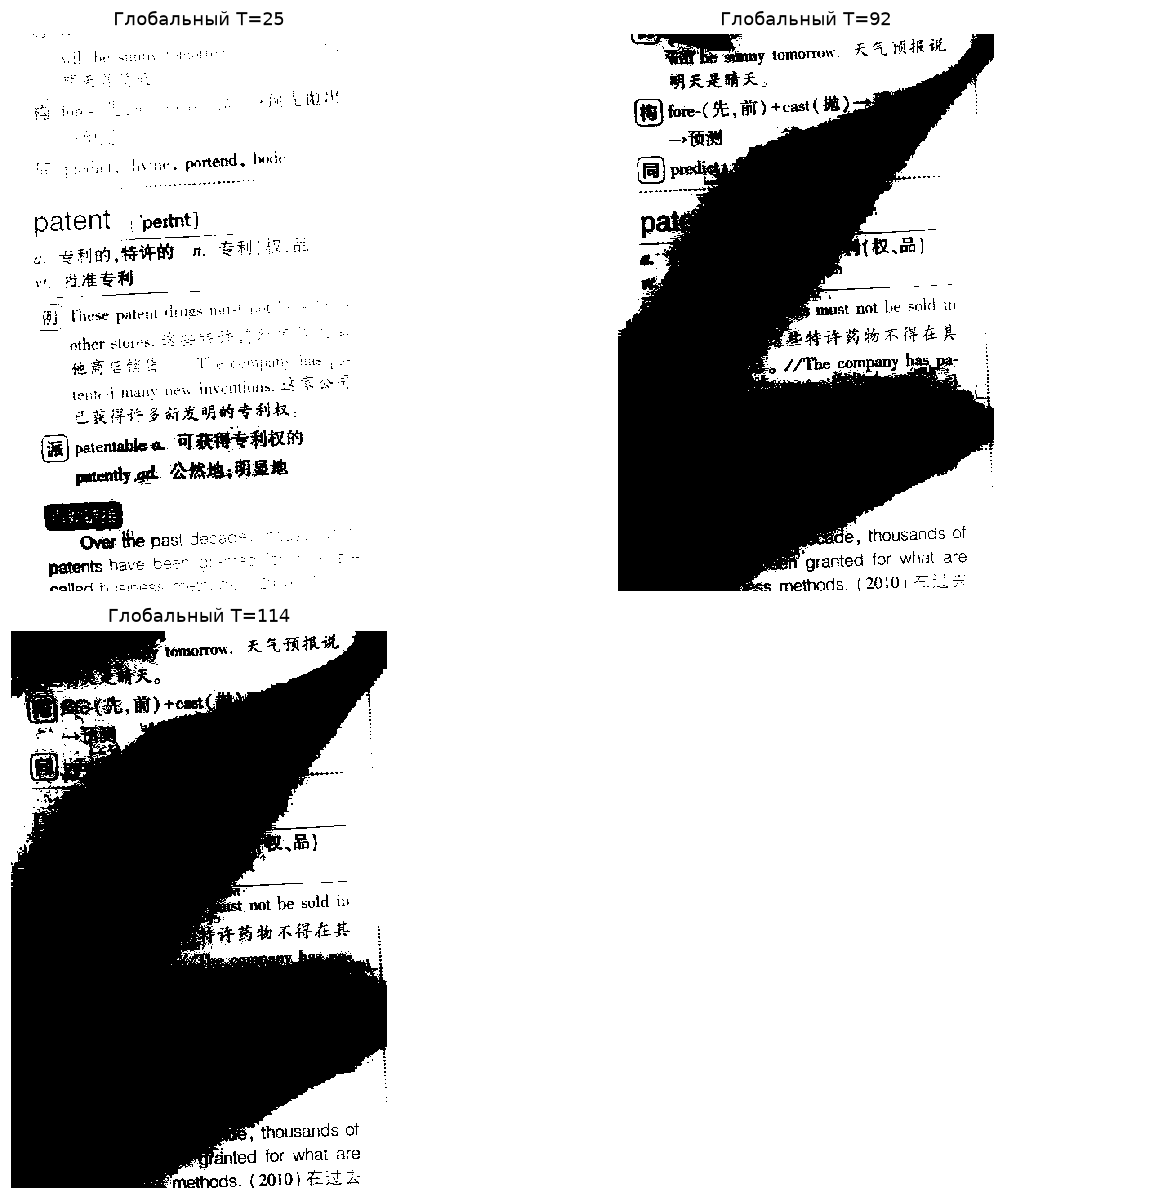

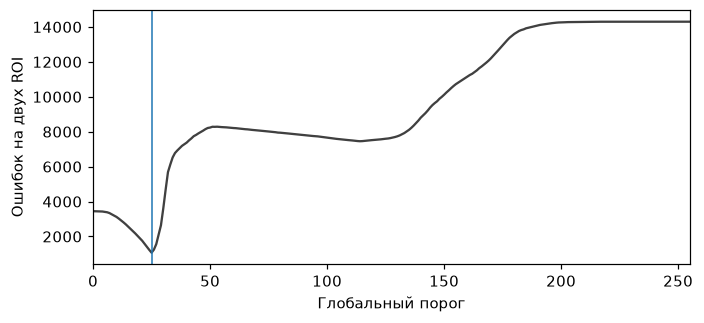

In [8]:
# Сверяем все 256 глобальных порогов на двух выбранных областях.
def roi_error(binary_image):
    return sum(np.count_nonzero(binary_image[y0:y1, x0:x1] != reference)
               for (y0, y1, x0, x1), reference in zip(rois, references))

errors = []
for threshold in range(256):
    errors.append(sum(np.count_nonzero(binarize(crop, threshold) != reference)
                      for crop, reference in zip(crops, references)))
best_global_t = int(np.argmin(errors))
global_t = otsu_threshold(photo)
total_roi_pixels = sum(crop.size for crop in crops)
print(f'Лучший глобальный порог по ROI: {best_global_t}')
print(f'Остаточная ошибка: {errors[best_global_t]} / {total_roi_pixels} '
      f'({100 * errors[best_global_t] / total_roi_pixels:.2f}%)')
print(f'Глобальный Оцу: T={global_t}, ошибка={roi_error(binarize(photo, global_t))} пикселей')

black_max = max(int(crop[reference == 0].max()) for crop, reference in zip(crops, references))
white_min = min(int(crop[reference == 255].min()) for crop, reference in zip(crops, references))
print(f'Условия сохранения опорных классов: T >= {black_max} и T < {white_min}.')
print(f'Перекрытие яркостей текста и бумаги: {black_max - white_min + 1} уровней.')

thresholds = sorted(set([*local_thresholds, best_global_t, global_t]))
show_images([binarize(photo, t) for t in thresholds],
            [f'Глобальный T={t}' for t in thresholds], cols=2, figsize=(12, 11))
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(errors, color='0.25')
ax.axvline(best_global_t, color='tab:blue', lw=1)
ax.set(xlabel='Глобальный порог', ylabel='Ошибок на двух ROI', xlim=(0, 255))
plt.show()

## 5. Гамма-коррекция фотографии

При $\gamma>0$ функция монотонна. Порог после гаммы соответствует одному
порогу исходной яркости. Перекрытие яркостей текста и бумаги сохраняется:
лучший результат среди всех исходных порогов задаёт нижнюю границу ошибки.
Округление к 8 битам дополнительно объединяет соседние уровни.

Гамма=0.35, T=165, ошибка на ROI= 8024 (45.21%)
Гамма=0.50, T=141, ошибка на ROI= 7970 (44.90%)
Гамма=0.70, T=117, ошибка на ROI= 7889 (44.45%)


Гамма=1.00, T= 92, ошибка на ROI= 7781 (43.84%)
Гамма=1.40, T= 72, ошибка на ROI= 7611 (42.88%)
Гамма=2.00, T= 57, ошибка на ROI= 7538 (42.47%)
Гамма=3.00, T= 42, ошибка на ROI= 8802 (49.59%)


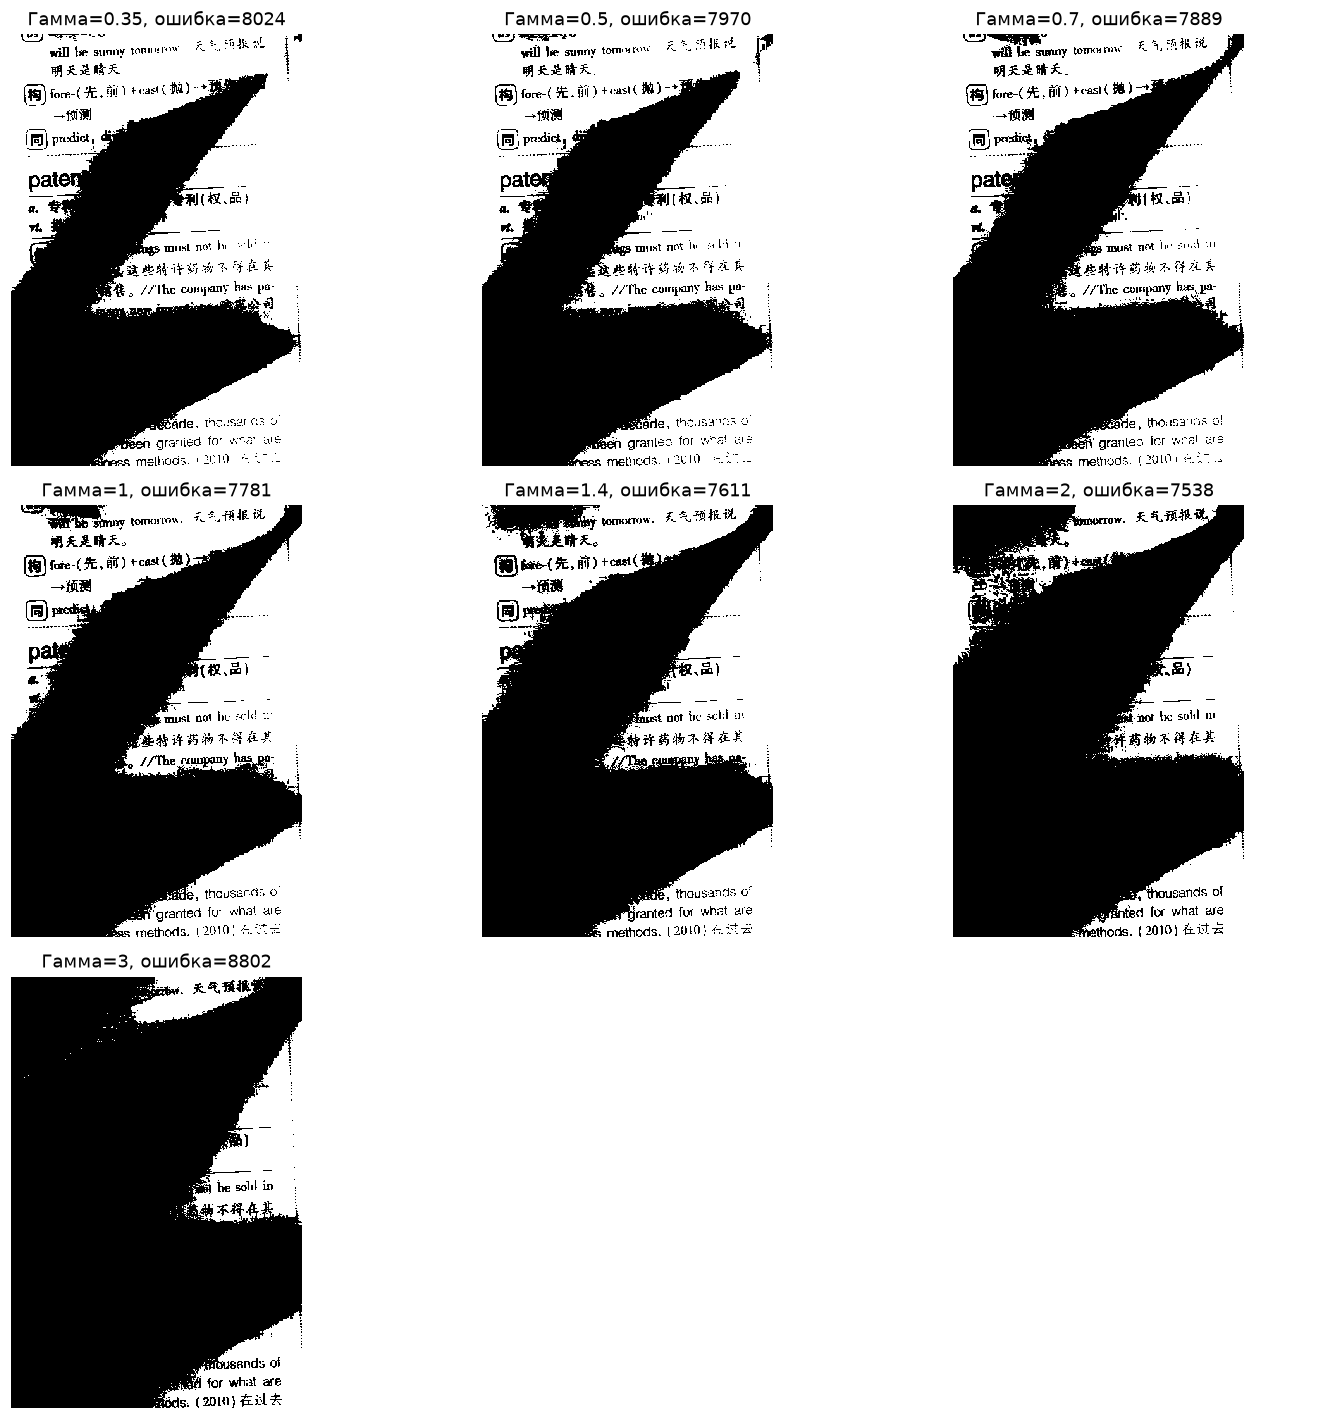

Лучший вариант в сетке: гамма=2.0, остаточная ошибка=7538 пикселей.


In [9]:
photo_gamma_results = []
for gamma in gammas:
    corrected = gamma_correct(photo, gamma)
    threshold = otsu_threshold(corrected)
    binary = binarize(corrected, threshold)
    error = roi_error(binary)
    photo_gamma_results.append((error, abs(gamma - 1), gamma, threshold, binary))
    print(f'Гамма={gamma:4.2f}, T={threshold:3d}, ошибка на ROI={error:5d} '
          f'({100 * error / total_roi_pixels:.2f}%)')
photo_best = min(photo_gamma_results, key=lambda row: row[:2])
show_images([row[4] for row in photo_gamma_results],
            [f'Гамма={row[2]:g}, ошибка={row[0]}' for row in photo_gamma_results],
            cols=3, figsize=(13, 13))
print(f'Лучший вариант в сетке: гамма={photo_best[2]}, остаточная ошибка={photo_best[0]} пикселей.')

## Вывод

На сканах ручной порог и Оцу отделяют тёмные штрихи от светлой бумаги.
Подбор гаммы измерен относительно ручной разметки; для чистого скана гамма 1
служит естественным базовым вариантом. На фотографии тень создаёт
пересечение яркостей фона и текста. Полный перебор порогов оставляет
ошибки в отмеченных фрагментах. Следующий шаг — локальный порог из работы №9.

Формула Оцу и постановка локальной настройки: лекция курса
[«Яркостная обработка и бинаризация»](../06_Яркостная_обработка_и_бинаризация_изображений.pdf).